# Genetic drift

The Wright Fisher model, this time considering one locus but K possible alleles.

In [1]:
import math
from random import shuffle, randint
import matplotlib.pyplot as plt

In [2]:
class Population:
    """A population is an ensemble of individuals at a given generation.

    Attributes:
        size                The number of individuals in the population.
        generation          The number of the generation, starting from 0 and                       incrementing by 1 at each step.
        number_of_alleles   K different possible alleles
        individuals         The list of individuals.
                            An individual is represented by a locus with a certain allele version (0 to K-1).
        allele_frequency    The list of frequencies of the alleles in the                           population.
    """
    def __init__(self, generation:int, size:int, individuals:list[int], number_of_alleles:int):
        self.size = size
        self.generation = generation
        self.individuals = individuals
        self.number_of_alleles = number_of_alleles
        self.allele_frequencies = [individuals.count(i)/self.size for i in range(number_of_alleles)]



    def next_generation_no_selection(self):
        new_generation_individuals = [0]*self.size
        for i in range(self.size):
            new_generation_individuals[i] = self.individuals[randint(0,self.size-1)]
        generation = self.generation + 1
        shuffle(new_generation_individuals)
        return Population(generation, self.size, new_generation_individuals,self.number_of_alleles)



def initialize_population(size:int, allele_frequencies:list[float]):
    allele_numbers = [math.floor(x*size) for x in allele_frequencies]
    individuals = []
    for i in range(len(allele_frequencies)):
        individuals += [i]*allele_numbers[i]
    shuffle(individuals)
    return Population(generation=int(0), size=size, individuals=individuals, number_of_alleles=len(allele_frequencies))


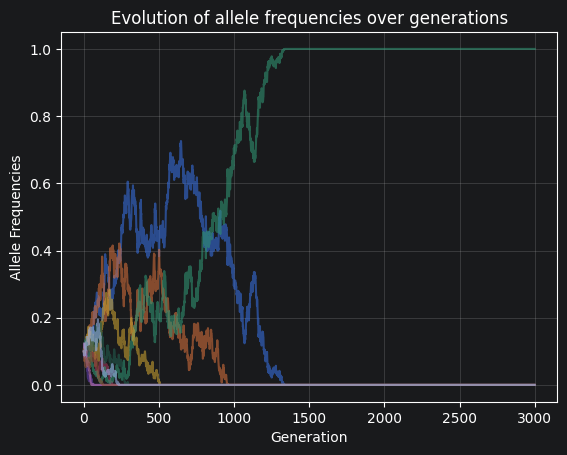

In [8]:
N = 1000
K = 10
allele_initial_frequencies = [1/K]*K
current_generation = initialize_population(N, allele_initial_frequencies)
generations = [0]

allele_frequencies_in_time = {f'allele_frequency_{i}': [allele_initial_frequencies[i]] for i in range(0,K)}

T = 3000

for t in range(1,T+1):
    next_generation = current_generation.next_generation_no_selection()
    allele_frequencies_list = next_generation.allele_frequencies

    for i in range(K):
        allele_frequencies_in_time[f'allele_frequency_{i}'].append(allele_frequencies_list[i])

    generations.append(t)
    current_generation = next_generation

for i in range(K):
    plt.plot(generations, allele_frequencies_in_time[f'allele_frequency_{i}'], alpha=0.6)
plt.xlabel("Generation")
plt.ylabel("Allele Frequencies")
plt.title("Evolution of allele frequencies over generations")
plt.grid(alpha=0.3)
plt.show()

In [12]:
def calculate_diversity(individuals:list[int]):
    tries = 1000
    diversity=0
    for i in range(tries):
        a = randint(0,len(individuals)-1)
        b = randint(0,len(individuals)-1)
        if individuals[a]!=individuals[b]:
            diversity+=1
    return diversity/tries

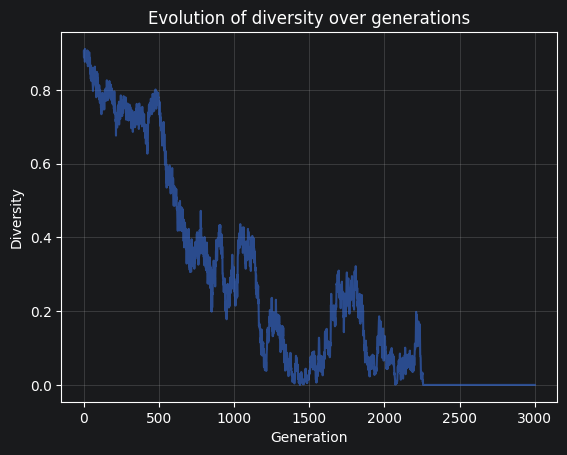

In [13]:
N = 1000
K = 10
allele_initial_frequencies = [1/K]*K
current_generation = initialize_population(N, allele_initial_frequencies)
generations = [0]
diversity_in_time=[calculate_diversity(current_generation.individuals)]

T = 3000

for t in range(1,T+1):
    next_generation = current_generation.next_generation_no_selection()
    diversity_in_time.append(calculate_diversity(next_generation.individuals))
    generations.append(t)
    current_generation = next_generation

plt.plot(generations, diversity_in_time, alpha=0.6)
plt.xlabel("Generation")
plt.ylabel("Diversity")
plt.title("Evolution of diversity over generations")
plt.grid(alpha=0.3)
plt.show()

Genetic drift => Diversity decreases in time.